# 01 · Data Ingestion, Data Lake on S3 and Exploratory Data Analysis
**AAI-540 Group 3 — CloudTrail Suspicious-Activity Classifier**

| | |
|---|---|
| **Goal** | Get the raw flAWS.cloud CloudTrail logs into an S3 data lake, convert them to an analysis-friendly format, and understand the data before engineering features. |
| **Input** | Public dataset: <https://summitroute.com/blog/2020/10/09/public_dataset_of_cloudtrail_logs_from_flaws_cloud/> (20 gzip-JSON files, 1,939,207 events, 2017-02-12 → 2020-10-07) |
| **Output (S3)** | `raw/flaws_cloudtrail_logs.tar` (untouched original) · `processed/events/part-*.parquet` (one flat row per event) |
| **Next** | `02_feature_engineering_feature_store.ipynb` |

**Recommended Studio instance:** `ml.t3.medium` is enough for this notebook.

## 1. Setup

In [1]:
# Install the project's pinned libraries (run once per kernel, BEFORE any other import).
# The pin keeps the SageMaker Python SDK on v2, which all notebooks in this repo use.
%pip install -q -r ../requirements.txt

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sagemaker-studio 1.1.32 requires pymongo-auth-aws>=1.3.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongosql>=0.7.2, which is not installed.
skops 0.15.0 requires prettytable>=3.9, which is not installed.
sagemaker-mlops 1.12.0 requires sagemaker-core>=2.12.0, but you have sagemaker-core 1.0.78 which is incompatible.
sagemaker-serve 1.12.0 requires sagemaker-core>=2.12.0, but you have sagemaker-core 1.0.78 which is incompatible.
sagemaker-train 1.14.0 requires sagemaker-core>=2.14.0, but you have sagemaker-core 1.0.78 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # shared project package: src/cloudtrail_mlops
DATA_DIR = Path.home() / "cloudtrail-data"           # local working copy, outside the git repo
DATA_DIR.mkdir(exist_ok=True)
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"] = "1"         # we intentionally pin SDK v2 (see requirements.txt)

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from cloudtrail_mlops import aws, config, ingest
from cloudtrail_mlops.plots import BLUE, ORANGE, SERIES, setup_style

setup_style()
pd.set_option("display.max_columns", 50)

ctx = aws.get_context()
print(f"Region: {ctx.region}\nBucket: {ctx.bucket}\nRole:   {ctx.role}")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
Region: us-east-1
Bucket: sagemaker-us-east-1-674905628044
Role:   arn:aws:iam::674905628044:role/LabRole


### S3 data-lake layout
Every artefact of the project lives under one prefix in the SageMaker default bucket, so the whole system can be found (and cleaned up) in one place. This table is also documented in `docs/data_catalog.md`.

In [2]:
pd.DataFrame([{"area": area, "S3 location": ctx.s3_uri(area)} for area in config.S3_LAYOUT])

,area,S3 location
0,raw,s3://sagemaker-us-east-1-674905628044/cloudtra...
1,events,s3://sagemaker-us-east-1-674905628044/cloudtra...
2,features,s3://sagemaker-us-east-1-674905628044/cloudtra...
3,model_input,s3://sagemaker-us-east-1-674905628044/cloudtra...
4,training,s3://sagemaker-us-east-1-674905628044/cloudtra...
5,batch,s3://sagemaker-us-east-1-674905628044/cloudtra...
6,datacapture,s3://sagemaker-us-east-1-674905628044/cloudtra...
7,monitoring,s3://sagemaker-us-east-1-674905628044/cloudtra...
8,pipeline,s3://sagemaker-us-east-1-674905628044/cloudtra...


## 2. Download the raw archive and store it in S3 (raw zone)
The archive is downloaded once, its MD5 checksum is compared with the published value (proves we have the genuine dataset), and the **untouched original** is copied to the raw zone of the data lake.

In [3]:
archive = ingest.download_file(config.DATA_URL, DATA_DIR / "flaws_cloudtrail_logs.tar")
checksum = ingest.md5_of(archive)
print(f"{archive.name}: {archive.stat().st_size / 2**20:.0f} MiB | md5 {checksum} | matches published: {checksum == config.DATA_MD5}")

raw_uri = ctx.session.upload_data(str(archive), bucket=ctx.bucket, key_prefix=ctx.prefix("raw"))
print("Raw archive stored at", raw_uri)

flaws_cloudtrail_logs.tar: 240 MiB | md5 4f0481c6be700ffc7610dbbf8cee5578 | matches published: True
Raw archive stored at s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/raw/flaws_cloudtrail_logs.tar


## 3. Flatten the JSON events to Parquet (processed zone)
CloudTrail events are deeply nested JSON. `ingest.flatten_event` keeps the 17 fields the model needs (who, what, where, when, outcome) and writes **one typed Parquet file per source file**. Processing one file at a time keeps memory usage low, and Parquet is ~10x smaller and much faster to query than JSON.

In [4]:
json_files = ingest.safe_extract(archive, DATA_DIR / "raw")
EVENTS_DIR = DATA_DIR / "events"
file_summary = ingest.convert_to_parquet(json_files, EVENTS_DIR)

print(f"{len(json_files)} files -> {file_summary.events.sum():,} events (expected {config.EXPECTED_RAW_EVENTS:,})")
assert file_summary.events.sum() == config.EXPECTED_RAW_EVENTS, "event count differs from the published dataset"
file_summary

20 files -> 1,939,207 events (expected 1,939,207)


,source_file,events,first_event,last_event
0,flaws_cloudtrail00.json.gz,100000,2017-02-12 19:57:06+00:00,2018-04-17 10:08:59+00:00
1,flaws_cloudtrail01.json.gz,100000,2018-04-17 10:09:00+00:00,2019-01-08 20:29:24+00:00
2,flaws_cloudtrail02.json.gz,100000,2019-01-08 20:30:01+00:00,2019-06-25 04:38:42+00:00
3,flaws_cloudtrail03.json.gz,100000,2019-06-25 04:38:42+00:00,2019-08-21 08:03:00+00:00
4,flaws_cloudtrail04.json.gz,100000,2019-08-21 08:03:00+00:00,2019-08-21 11:31:47+00:00
5,flaws_cloudtrail05.json.gz,100000,2019-08-21 11:31:47+00:00,2019-08-21 15:18:55+00:00
6,flaws_cloudtrail06.json.gz,100000,2019-08-21 15:18:55+00:00,2019-08-21 19:23:21+00:00
7,flaws_cloudtrail07.json.gz,100000,2019-08-21 19:23:21+00:00,2019-08-21 23:56:32+00:00
8,flaws_cloudtrail08.json.gz,100000,2019-08-21 23:56:32+00:00,2019-08-22 03:22:23+00:00
9,flaws_cloudtrail09.json.gz,100000,2019-08-22 03:22:23+00:00,2019-08-22 07:27:49+00:00


In [5]:
events_uri = ctx.session.upload_data(str(EVENTS_DIR), bucket=ctx.bucket, key_prefix=ctx.prefix("events"))
aws.save_state(ctx, raw_uri=raw_uri, events_uri=events_uri)
print("Processed events stored at", events_uri)

Processed events stored at s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/processed/events


## 4. Exploratory data analysis
DuckDB queries the Parquet files directly with SQL (no need to load 1.9 M rows into pandas).

### 4.1 Size, period and duplicates

In [6]:
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")
con.execute(f"CREATE VIEW events AS SELECT * FROM read_parquet('{(EVENTS_DIR / 'part-*.parquet').as_posix()}')")
con.execute("CREATE TABLE unique_events AS SELECT * FROM events QUALIFY ROW_NUMBER() OVER (PARTITION BY event_id ORDER BY event_time) = 1")

overview = con.sql('''
    SELECT (SELECT COUNT(*) FROM events)              AS raw_events,
           COUNT(*)                                   AS unique_events,
           MIN(event_time)                            AS first_event,
           MAX(event_time)                            AS last_event,
           COUNT(DISTINCT actor_id)                   AS actors,
           COUNT(DISTINCT source_ip)                  AS source_ips,
           COUNT(DISTINCT user_agent)                 AS user_agents,
           COUNT(DISTINCT event_name)                 AS distinct_apis
    FROM unique_events''').df()
overview.T.rename(columns={0: "value"})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,value
raw_events,1939207
unique_events,1225784
first_event,2017-02-12 19:57:06+00:00
last_event,2020-10-07 21:03:30+00:00
actors,185
source_ips,9402
user_agents,8811
distinct_apis,1242


**Observation.** The public archive repeats a large share of events (the same `eventID` appears in more than one file), so **de-duplication on `eventID` is a mandatory pre-processing step** — otherwise duplicated activity would be counted twice in every behavioural feature. All analysis below uses unique events.

### 4.2 Activity over time

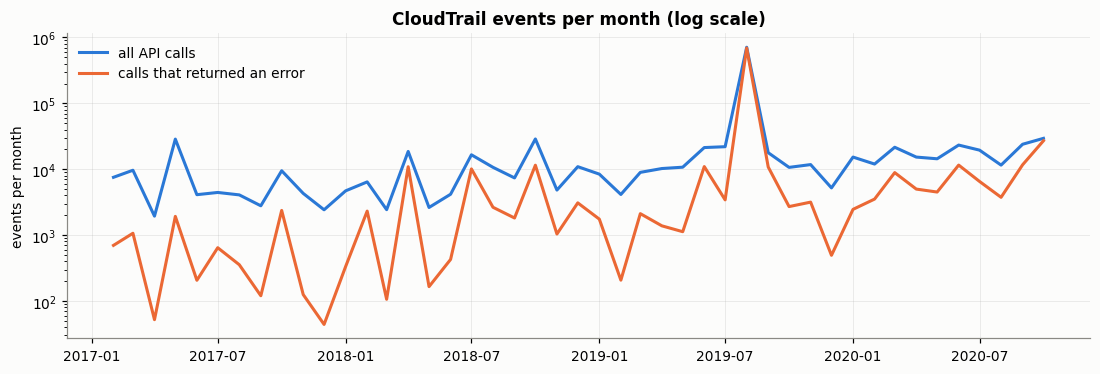

In [7]:
monthly = con.sql('''
    SELECT date_trunc('month', event_time) AS month, COUNT(*) AS events,
           SUM(CASE WHEN error_code IS NOT NULL THEN 1 ELSE 0 END) AS failed_calls
    FROM unique_events GROUP BY 1 ORDER BY 1''').df()

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(monthly.month, monthly.events, color=BLUE, label="all API calls")
ax.plot(monthly.month, monthly.failed_calls, color=ORANGE, label="calls that returned an error")
ax.set_yscale("log")
ax.set(title="CloudTrail events per month (log scale)", ylabel="events per month")
ax.legend(loc="upper left")
plt.show()

**Observation.** Volume is very uneven over time (bursts of several hundred thousand events in some months, quiet months in others) and a large fraction of calls fail. This matters for two design decisions:
* the **train / validation / test split must be chronological** (a model has to work on *future* activity), and
* features should describe **behaviour relative to the actor's own history**, not absolute volumes that change with the size of the log.

### 4.3 Who is acting, and which services do they use?

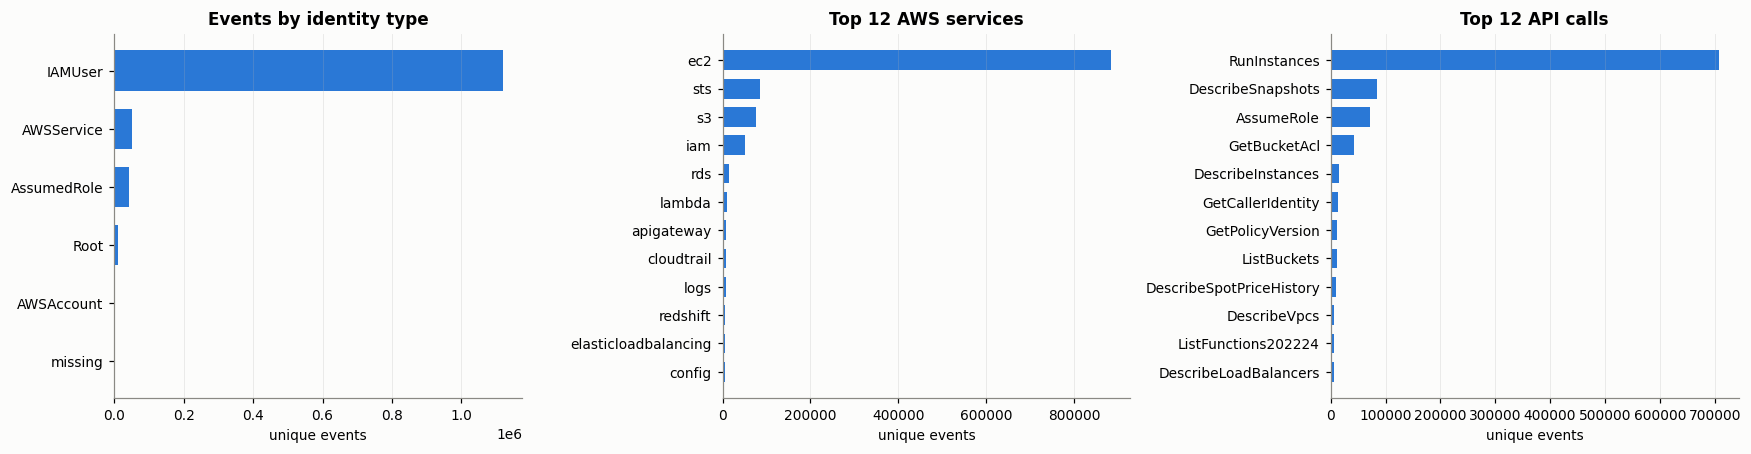

In [8]:
identity = con.sql("SELECT COALESCE(identity_type, 'missing') AS identity_type, COUNT(*) AS events FROM unique_events GROUP BY 1 ORDER BY 2 DESC").df()
services = con.sql("SELECT replace(event_source, '.amazonaws.com', '') AS service, COUNT(*) AS events FROM unique_events GROUP BY 1 ORDER BY 2 DESC LIMIT 12").df()
apis = con.sql("SELECT event_name, COUNT(*) AS events FROM unique_events GROUP BY 1 ORDER BY 2 DESC LIMIT 12").df()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, frame, label, title in ((axes[0], identity, "identity_type", "Events by identity type"),
                                (axes[1], services, "service", "Top 12 AWS services"),
                                (axes[2], apis, "event_name", "Top 12 API calls")):
    frame = frame.iloc[::-1]
    ax.barh(frame[label], frame.events, color=BLUE, height=0.7)
    ax.set(title=title, xlabel="unique events")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Observations.**
* Most activity comes from **IAM users**; **root-account** activity is a small but security-relevant slice.
* **EC2 and STS dominate** (instance / snapshot enumeration and `AssumeRole`), followed by S3 and IAM. Rare services will be learned less well — evaluation should be read with that in mind.
* The most frequent calls are read / enumeration calls (`Describe*`, `List*`, `Get*`). Reconnaissance and routine administration look alike call-by-call, which is why the model works on **windows of activity per actor** rather than single events.

### 4.4 Errors and authorisation failures

In [9]:
errors = con.sql('''
    SELECT COALESCE(error_code, 'NO_ERROR') AS error_code, COUNT(*) AS events,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM unique_events GROUP BY 1 ORDER BY 2 DESC LIMIT 10''').df()
errors

,error_code,events,pct
0,Client.RequestLimitExceeded,410209,33.47
1,NO_ERROR,358121,29.22
2,Client.UnauthorizedOperation,192651,15.72
3,AccessDenied,105220,8.58
4,Client.Unsupported,55496,4.53
5,Server.InsufficientInstanceCapacity,33628,2.74
6,NoSuchBucket,28811,2.35
7,Client.InstanceLimitExceeded,25050,2.04
8,Client.InvalidParameterValue,2402,0.20
9,Client.DryRunOperation,1738,0.14


**Observation.** Authorisation failures (`AccessDenied`, `Client.UnauthorizedOperation`) are common — the flAWS environment is a public security CTF, so many callers probe permissions they do not have. Error counts and **authorisation-error rates per window** become features; capacity errors (`InstanceLimitExceeded`, …) are kept separate because they are not security signals.

### 4.5 Weak labels: how often do the security policy rules fire?
There are no analyst-confirmed "attack" labels in this dataset, so (as stated in the design document) we use **rule-based weak labels**. An event is *policy-flagged* if it matches one of four high-risk patterns:

| rule | API calls |
|---|---|
| audit tampering | `StopLogging`, `DeleteTrail`, `UpdateTrail`, `PutEventSelectors`, `DeleteEventDataStore` |
| public exposure | `PutBucketPolicy`, `PutBucketAcl`, `DeletePublicAccessBlock`, `Put*PublicAccessBlock` |
| credential / privilege change | `CreateAccessKey`, `Attach*Policy`, `Put*Policy`, `CreatePolicyVersion`, `SetDefaultPolicyVersion` |
| console login without MFA | `ConsoleLogin` with `mfaAuthenticated = false` |

The model never sees these API names directly; it has to recognise the **behaviour around them** (see notebook 02).

Policy-flagged events: 361 of 1,225,784 unique events (0.029 %)


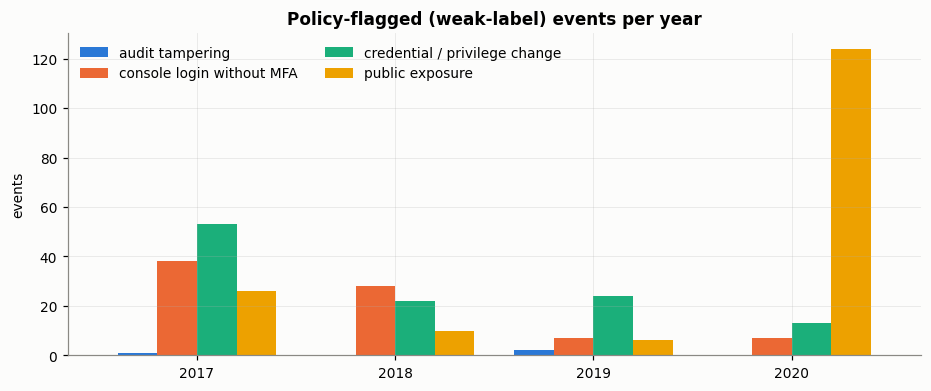

year,2017,2018,2019,2020
policy_rule,,,,
audit tampering,1,0,2,0
console login without MFA,38,28,7,7
credential / privilege change,53,22,24,13
public exposure,26,10,6,124


In [10]:
policy = con.sql('''
    SELECT CASE
             WHEN event_name IN ('StopLogging','DeleteTrail','UpdateTrail','PutEventSelectors','DeleteEventDataStore') THEN 'audit tampering'
             WHEN event_name IN ('PutBucketPolicy','PutBucketAcl','DeletePublicAccessBlock','PutBucketPublicAccessBlock','PutAccountPublicAccessBlock') THEN 'public exposure'
             WHEN event_name IN ('CreateAccessKey','AttachUserPolicy','AttachRolePolicy','PutUserPolicy','PutRolePolicy','CreatePolicyVersion','SetDefaultPolicyVersion') THEN 'credential / privilege change'
             WHEN event_name = 'ConsoleLogin' AND NOT COALESCE(mfa_authenticated, FALSE) THEN 'console login without MFA'
           END AS policy_rule,
           date_part('year', event_time) AS year, COUNT(*) AS events
    FROM unique_events GROUP BY ALL HAVING policy_rule IS NOT NULL''').df()

table = policy.pivot_table(index="policy_rule", columns="year", values="events", aggfunc="sum", fill_value=0)
total_unique = int(overview.unique_events[0])
print(f"Policy-flagged events: {int(table.values.sum()):,} of {total_unique:,} unique events "
      f"({100 * table.values.sum() / total_unique:.3f} %)")

ax = table.T.plot(kind="bar", figsize=(10, 3.8), color=SERIES[:len(table)], width=0.8)
ax.set(title="Policy-flagged (weak-label) events per year", xlabel="", ylabel="events")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="", ncol=2)
plt.show()
table

**Observation — the key modelling challenge.** Policy-flagged events are **extremely rare** (well under 1 % of events). Consequences carried into the design:
* **accuracy is meaningless** (predicting "normal" for everything would be > 99 % accurate) → we evaluate with ROC-AUC, average precision and recall at a fixed analyst alert budget;
* class imbalance is handled with XGBoost's `scale_pos_weight` instead of over-sampling (SMOTE would invent synthetic "future" activity in a time series);
* the four rule categories are unevenly spread over the years, so the time-based test period contains a different mix than training — exactly the drift the monitoring in notebook 05 watches for.

### 4.6 When does activity happen?

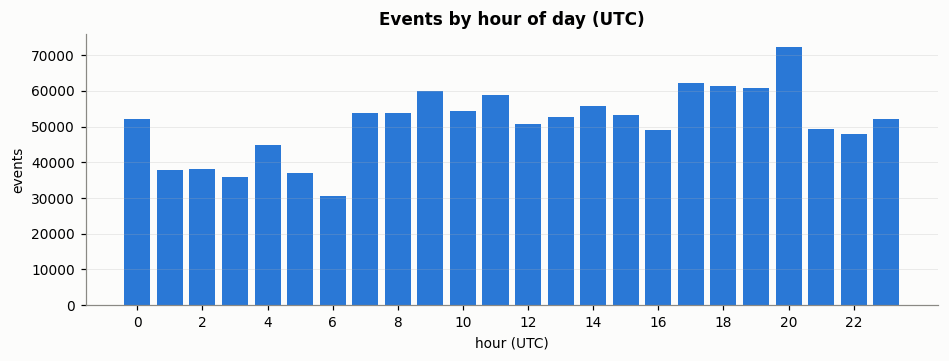

In [11]:
hourly = con.sql('''
    SELECT EXTRACT(hour FROM event_time) AS hour_utc, COUNT(*) AS events
    FROM unique_events GROUP BY 1 ORDER BY 1''').df()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(hourly.hour_utc, hourly.events, color=BLUE, width=0.8)
ax.set(title="Events by hour of day (UTC)", xlabel="hour (UTC)", ylabel="events", xticks=range(0, 24, 2))
ax.grid(axis="x", visible=False)
plt.show()

**Observation.** Activity runs around the clock (automated scanners and SDK scripts dominate), so "off-hours" alone is a weak signal; it is kept as one feature (`off_hours_count`) together with a cyclical hour / weekday encoding.

## 5. Summary
* Raw data stored untouched in the **S3 raw zone**; 1.94 M events flattened to Parquet in the **processed zone**.
* De-duplication on `eventID` is required.
* The positive class (policy-flagged activity) is very rare and time-varying → chronological split, ranking metrics, imbalance weighting, drift monitoring.
* Single events are ambiguous → aggregate to **actor × 5-minute windows** with history features (next notebook).

In [12]:
con.close()